In [1]:
%pip install -q transformers datasets gradio scikit-learn pandas matplotlib pillow

In [2]:
import os
import re
from collections import Counter

import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd

from datasets import load_dataset
from PIL import Image
from transformers import pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

MODEL_NAME = "dima806/chest_xray_pneumonia_detection"

model = pipeline(
    "image-classification",
    model=MODEL_NAME
)

print("Model loaded successfully!")

Libraries imported successfully.


config.json:   0%|          | 0.00/738 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model loaded successfully!


In [3]:
import os
import re
from collections import Counter

import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd

from datasets import load_dataset
from PIL import Image
from transformers import pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

MODEL_NAME = "dima806/chest_xray_pneumonia_detection"

model = pipeline(
    "image-classification",
    model=MODEL_NAME
)

print("Model loaded successfully!")

Libraries imported successfully.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model loaded successfully!


In [4]:
DATASET_NAME = "Hassaan90/chest-xray-pneumonia"

dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("Dataset stream loaded successfully.")


def get_label_and_patient_id(item):
    """
    Extract the class label and an approximate patient ID
    from the image path.
    """
    key = item.get("__key__", "")
    parts = key.split("/")

    if len(parts) < 4 or "/test/" not in f"/{key}/":
        return None, None

    folder = parts[2].upper()

    if folder == "NORMAL":
        label = "NORMAL"
    elif folder in {"BACTERIA", "VIRUS", "PNEUMONIA"}:
        label = "PNEUMONIA"
    else:
        return None, None

    filename = parts[-1]

    # Remove a trailing image sequence such as -0001.
    patient_id = re.sub(r"-\d{4}$", "", filename)

    return label, patient_id


# Select a small, balanced exploratory sample.
# Try to avoid selecting multiple images with the same approximate ID.
TARGET_PER_CLASS = 10
MAX_ITEMS_TO_SCAN = 50000

balanced_samples = []
selected_patient_ids = {
    "NORMAL": set(),
    "PNEUMONIA": set()
}
selected_counts = Counter()

shuffled_dataset = dataset.shuffle(
    seed=42,
    buffer_size=2000
)

for index, item in enumerate(shuffled_dataset):
    if index >= MAX_ITEMS_TO_SCAN:
        break

    true_label, patient_id = get_label_and_patient_id(item)

    if true_label is None:
        continue

    if selected_counts[true_label] >= TARGET_PER_CLASS:
        continue

    if patient_id in selected_patient_ids[true_label]:
        continue

    balanced_samples.append(item)
    selected_patient_ids[true_label].add(patient_id)
    selected_counts[true_label] += 1

    if all(
        selected_counts[label] >= TARGET_PER_CLASS
        for label in ("NORMAL", "PNEUMONIA")
    ):
        break

print("Images selected:", len(balanced_samples))
print("Class counts:", dict(selected_counts))

if (
    selected_counts["NORMAL"] < TARGET_PER_CLASS
    or selected_counts["PNEUMONIA"] < TARGET_PER_CLASS
):
    raise RuntimeError(
        "Not enough images were found for both classes. "
        "Increase MAX_ITEMS_TO_SCAN and rerun this cell."
    )

README.md:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

Dataset stream loaded successfully.
Images selected: 20
Class counts: {'NORMAL': 10, 'PNEUMONIA': 10}


In [5]:
evaluation_rows = []
y_true = []
y_pred = []

for item in balanced_samples:
    true_label, patient_id = get_label_and_patient_id(item)

    # The dataset already provides a PIL image.
    image = item["jpeg"].convert("RGB")

    predictions = model(image)

    scores = {
        entry["label"].upper(): float(entry["score"])
        for entry in predictions
    }

    normal_score = scores.get("NORMAL", 0.0)
    pneumonia_score = scores.get("PNEUMONIA", 0.0)

    if "NORMAL" not in scores and "PNEUMONIA" not in scores:
        raise ValueError(
            f"Unexpected model labels: {list(scores.keys())}"
        )

    predicted_label = (
        "NORMAL"
        if normal_score >= pneumonia_score
        else "PNEUMONIA"
    )

    y_true.append(true_label)
    y_pred.append(predicted_label)

    evaluation_rows.append({
        "Image ID": item["__key__"].split("/")[-1],
        "Approximate patient ID": patient_id,
        "True label": true_label,
        "Predicted label": predicted_label,
        "Correct": true_label == predicted_label,
        "NORMAL score (%)": round(normal_score * 100, 2),
        "PNEUMONIA score (%)": round(pneumonia_score * 100, 2)
    })

evaluation_df = pd.DataFrame(evaluation_rows)

labels = ["NORMAL", "PNEUMONIA"]

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    pos_label="PNEUMONIA",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    pos_label="PNEUMONIA",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    pos_label="PNEUMONIA",
    zero_division=0
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

print(f"Images evaluated: {len(y_true)}")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision (PNEUMONIA): {precision:.2%}")
print(f"Recall (PNEUMONIA): {recall:.2%}")
print(f"F1-score (PNEUMONIA): {f1:.2%}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    zero_division=0
))

print("Confusion matrix:")
print(cm)

display(evaluation_df)

CSV_PATH = "chest_xray_evaluation.csv"

evaluation_df.to_csv(
    CSV_PATH,
    index=False
)

print(f"Evaluation results saved to {CSV_PATH}")

Images evaluated: 20
Accuracy: 95.00%
Precision (PNEUMONIA): 90.91%
Recall (PNEUMONIA): 100.00%
F1-score (PNEUMONIA): 95.24%

Classification report:
              precision    recall  f1-score   support

      NORMAL       1.00      0.90      0.95        10
   PNEUMONIA       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20

Confusion matrix:
[[ 9  1]
 [ 0 10]]


,Image ID,Approximate patient ID,True label,Predicted label,Correct,NORMAL score (%),PNEUMONIA score (%)
0,NORMAL-724740-0001,NORMAL-724740,NORMAL,NORMAL,True,94.03,5.97
1,NORMAL-706052-0001,NORMAL-706052,NORMAL,NORMAL,True,91.86,8.14
2,BACTERIA-7257218-0002,BACTERIA-7257218,PNEUMONIA,PNEUMONIA,True,3.44,96.56
3,NORMAL-7695736-0001,NORMAL-7695736,NORMAL,NORMAL,True,61.68,38.32
4,BACTERIA-1768914-0002,BACTERIA-1768914,PNEUMONIA,PNEUMONIA,True,5.57,94.43
5,BACTERIA-5660566-0006,BACTERIA-5660566,PNEUMONIA,PNEUMONIA,True,7.08,92.92
6,BACTERIA-9242636-0004,BACTERIA-9242636,PNEUMONIA,PNEUMONIA,True,4.30,95.70
7,NORMAL-7488601-0001,NORMAL-7488601,NORMAL,NORMAL,True,92.78,7.22
8,NORMAL-5601980-0001,NORMAL-5601980,NORMAL,NORMAL,True,86.65,13.35
9,VIRUS-5180281-0001,VIRUS-5180281,PNEUMONIA,PNEUMONIA,True,3.73,96.27


Evaluation results saved to chest_xray_evaluation.csv


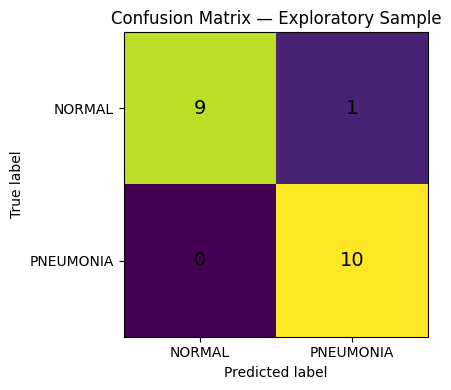

In [6]:
def create_confusion_matrix():
    fig, ax = plt.subplots(figsize=(6, 4))

    ax.imshow(cm, interpolation="nearest")

    ax.set_title("Confusion Matrix — Exploratory Sample")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    ax.set_xticks([0, 1], labels=labels)
    ax.set_yticks([0, 1], labels=labels)

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14
            )

    fig.tight_layout()
    return fig


fig = create_confusion_matrix()
plt.show()

In [7]:
def predict_xray(image_path):
    """
    Predict a label for one image.
    Educational use only; not a medical diagnosis.
    """
    image = Image.open(image_path).convert("RGB")

    predictions = model(image)

    for item in predictions:
        label = item["label"]
        score = item["score"] * 100

        print(f"{label}: {score:.2f}%")


print("Prediction function is ready.")

Prediction function is ready.


In [8]:
def analyze_uploaded_images(files):
    columns = [
        "Image",
        "Prediction",
        "NORMAL score (%)",
        "PNEUMONIA score (%)"
    ]

    if not files:
        return [], pd.DataFrame(columns=columns)

    displayed_images = []
    rows = []

    for file_path in files:
        try:
            image = Image.open(file_path).convert("RGB")
            filename = os.path.basename(file_path)

            displayed_images.append(
                (image.copy(), filename)
            )

            predictions = model(image)

            scores = {
                item["label"].upper(): float(item["score"])
                for item in predictions
            }

            normal_score = scores.get("NORMAL", 0.0)
            pneumonia_score = scores.get("PNEUMONIA", 0.0)

            prediction = (
                "NORMAL"
                if normal_score >= pneumonia_score
                else "PNEUMONIA"
            )

            rows.append({
                "Image": filename,
                "Prediction": prediction,
                "NORMAL score (%)": round(normal_score * 100, 2),
                "PNEUMONIA score (%)": round(
                    pneumonia_score * 100, 2
                )
            })

        except Exception as exc:
            rows.append({
                "Image": os.path.basename(str(file_path)),
                "Prediction": f"Error: {str(exc)[:100]}",
                "NORMAL score (%)": None,
                "PNEUMONIA score (%)": None
            })

    return displayed_images, pd.DataFrame(rows)


def show_evaluation():
    metrics_text = (
        f"Images evaluated: {len(y_true)}\n"
        f"Accuracy: {accuracy:.2%}\n"
        f"Precision (PNEUMONIA): {precision:.2%}\n"
        f"Recall (PNEUMONIA): {recall:.2%}\n"
        f"F1-score (PNEUMONIA): {f1:.2%}\n\n"
        "Exploratory evaluation only — not a medical diagnosis."
    )

    return (
        metrics_text,
        evaluation_df,
        create_confusion_matrix()
    )


with gr.Blocks() as demo:

    gr.Markdown(
        """
        # Chest X-ray Classifier

        An educational image-classification demo using a pretrained
        model to predict **NORMAL** or **PNEUMONIA**.

        **Important:** This is not a medical diagnostic tool.
        Do not use its predictions to make medical decisions.
        Model scores are not necessarily calibrated probabilities.
        """
    )

    with gr.Tabs():

        with gr.Tab("Analyze Images"):

            gr.Markdown(
                "Upload one or more chest X-ray images to view "
                "the model's predictions."
            )

            uploaded_files = gr.File(
                label="Upload chest X-ray images",
                file_count="multiple",
                file_types=["image"],
                type="filepath"
            )

            analyze_button = gr.Button(
                "Analyze Images",
                variant="primary"
            )

            displayed_images = gr.Gallery(
                label="Uploaded X-ray Images",
                columns=2,
                height="auto",
                object_fit="contain"
            )

            upload_results = gr.Dataframe(
                label="Prediction Results",
                interactive=False
            )

            analyze_button.click(
                fn=analyze_uploaded_images,
                inputs=uploaded_files,
                outputs=[
                    displayed_images,
                    upload_results
                ]
            )

        with gr.Tab("Model Evaluation"):

            gr.Markdown(
                """
                This exploratory evaluation uses a small sample of images.
                It does not establish clinical reliability or generalization.
                """
            )

            evaluate_button = gr.Button(
                "Show Evaluation",
                variant="primary"
            )

            metrics_output = gr.Textbox(
                label="Evaluation Metrics",
                lines=6
            )

            evaluation_table = gr.Dataframe(
                label="Image-by-image Results",
                interactive=False
            )

            confusion_plot = gr.Plot(
                label="Confusion Matrix"
            )

            evaluate_button.click(
                fn=show_evaluation,
                inputs=[],
                outputs=[
                    metrics_output,
                    evaluation_table,
                    confusion_plot
                ]
            )

    gr.Markdown(
        """
        **Disclaimer:** For educational purposes only.
        Never use these predictions to diagnose or treat a medical condition.
        """
    )

print("Gradio interface created successfully.")

Gradio interface created successfully.


In [9]:
demo.launch(
    share=True,
    theme=gr.themes.Soft()
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c14b2707fae424e6cf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
from google.colab import files

files.download(CSV_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

from pathlib import Path
from google.colab import files

readme_content = """# Chest X-Ray Pneumonia Classification

## Project Overview
This educational project uses a pretrained deep learning model to classify chest X-ray images into two categories: NORMAL and PNEUMONIA.

The project demonstrates a basic medical AI workflow using Python, Hugging Face Transformers, and Gradio.

## Model
- Model: dima806/chest_xray_pneumonia_detection
- Task: Image classification
- Output classes: NORMAL and PNEUMONIA

## Dataset
The project uses the Hugging Face dataset:
Hassaan90/chest-xray-pneumonia

A small, balanced sample of images is used for exploratory evaluation.

## Features
- Upload chest X-ray images for classification
- Display model prediction scores
- Evaluate predictions on a small sample
- Calculate accuracy, precision, recall, and F1-score
- Generate a confusion matrix
- Export evaluation results to CSV

## Technologies
- Python
- PyTorch
- Hugging Face Transformers
- Hugging Face Datasets
- Gradio
- Pandas
- Matplotlib
- Scikit-learn
- Pillow

## Project Files
- `Medical_AI_Project.ipynb`: Main project notebook
- `chest_xray_evaluation.csv`: Evaluation results
- `README.md`: Project documentation
- `requirements.txt`: Python dependencies

## Important Limitations
This project is for educational purposes only and is not intended for clinical use.

The evaluation uses a small sample and does not establish clinical accuracy or generalizability. Model prediction scores should not be interpreted as calibrated probabilities or as a measure of disease severity.

This project is not a substitute for professional medical assessment.

## How to Run
1. Open `Medical_AI_Project.ipynb` in Google Colab.
2. Run the notebook cells in order.
3. Upload one or more chest X-ray images in the Gradio interface.
4. Review the predictions and exploratory evaluation results.

## Author
Ladan Amini
"""

Path("README.md").write_text(readme_content, encoding="utf-8")

print("README.md created successfully.")
files.download("README.md")


README.md created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>